In [133]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [134]:
df = pd.read_excel("../data/online-retail.xlsx")

In [135]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [136]:
print(df.shape)

(541909, 8)


In [137]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [138]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [139]:
df['CustomerID'].isnull().mean()*100

np.float64(24.926694334288598)

In [140]:
df = df.dropna(subset=['Description'])
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133626
Country             0
dtype: int64


In [141]:
print(f'Duplicated rows : {df.duplicated().sum()}')

Duplicated rows : 5268


In [142]:
print(df['InvoiceNo'].apply(type).value_counts())

InvoiceNo
<class 'int'>    531164
<class 'str'>      9291
Name: count, dtype: int64


In [143]:
text_mask = df['InvoiceNo'].apply(lambda x: isinstance(x, str))
print(df[text_mask]['InvoiceNo'].unique()[:10])   

['C536379' 'C536383' 'C536391' 'C536506' 'C536543' 'C536548' 'C536606'
 'C536622' 'C536625' 'C536642']


In [144]:
print(df[df.duplicated(keep=False)].head(6))

    InvoiceNo StockCode                       Description  Quantity  \
485    536409     22111      SCOTTIE DOG HOT WATER BOTTLE         1   
489    536409     22866     HAND WARMER SCOTTY DOG DESIGN         1   
494    536409     21866       UNION JACK FLAG LUGGAGE TAG         1   
517    536409     21866       UNION JACK FLAG LUGGAGE TAG         1   
521    536409     22900   SET 2 TEA TOWELS I LOVE LONDON          1   
527    536409     22866     HAND WARMER SCOTTY DOG DESIGN         1   

            InvoiceDate  UnitPrice  CustomerID         Country  
485 2010-12-01 11:45:00       4.95     17908.0  United Kingdom  
489 2010-12-01 11:45:00       2.10     17908.0  United Kingdom  
494 2010-12-01 11:45:00       1.25     17908.0  United Kingdom  
517 2010-12-01 11:45:00       1.25     17908.0  United Kingdom  
521 2010-12-01 11:45:00       2.95     17908.0  United Kingdom  
527 2010-12-01 11:45:00       2.10     17908.0  United Kingdom  


In [145]:
df = df.drop_duplicates()
print('Duplicated Rows: ',df.duplicated().sum())
print('New Shape: ', df.shape)

Duplicated Rows:  0
New Shape:  (535187, 8)


In [146]:
c_orders = df['InvoiceNo'].apply(lambda x: isinstance(x, str) and x.startswith('C'))
print('Rows to remove : ', c_orders.sum())


df = df[~c_orders]

print(f"Remaining C rows: {df['InvoiceNo'].apply(lambda x: isinstance(x, str)).sum()}")
print('New shape:', df.shape)

Rows to remove :  9251
Remaining C rows: 3
New shape: (525936, 8)


In [147]:
text_mask = df['InvoiceNo'].apply(lambda x: isinstance(x, str))
print(df[text_mask]['InvoiceNo'].unique()[:10])   

['A563185' 'A563186' 'A563187']


In [148]:
a_orders = df['InvoiceNo'].apply(lambda x: isinstance(x, str) and x.startswith('A'))
df = df[~a_orders]
print('Final shape after removing cancelled + adjustment orders:', df.shape)

Final shape after removing cancelled + adjustment orders: (525933, 8)


In [149]:
negative_qty = df['Quantity'] < 0
print('Negative Quantity rows: ', negative_qty.sum())

print(df[negative_qty].head())

Negative Quantity rows:  474
      InvoiceNo StockCode Description  Quantity         InvoiceDate  \
7313     537032     21275           ?       -30 2010-12-03 16:50:00   
13217    537425    84968F       check       -20 2010-12-06 15:35:00   
13218    537426    84968E       check       -35 2010-12-06 15:36:00   
13264    537432    35833G     damages       -43 2010-12-06 16:10:00   
21338    538072     22423      faulty       -13 2010-12-09 14:10:00   

       UnitPrice  CustomerID         Country  
7313         0.0         NaN  United Kingdom  
13217        0.0         NaN  United Kingdom  
13218        0.0         NaN  United Kingdom  
13264        0.0         NaN  United Kingdom  
21338        0.0         NaN  United Kingdom  


In [150]:
df = df[~negative_qty]

print('Remaining negative Quantity rows:', (df['Quantity'] < 0).sum())
print('New shape:', df.shape)

Remaining negative Quantity rows: 0
New shape: (525459, 8)


In [151]:
bad_price = df['UnitPrice'] <= 0
print('UnitPrice <= 0 rows:', bad_price.sum())

print(df[bad_price].head(10))

UnitPrice <= 0 rows: 582
      InvoiceNo StockCode                       Description  Quantity  \
6391     536941     22734                            amazon        20   
6392     536942     22139                            amazon        15   
9302     537197     22841      ROUND CAKE TIN VINTAGE GREEN         1   
14335    537534     85064      CREAM SWEETHEART LETTER RACK         1   
14336    537534     84832  ZINC WILLIE WINKIE  CANDLE STICK         1   
14337    537534     84692       BOX OF 24 COCKTAIL PARASOLS         2   
14338    537534     48184             DOORMAT ENGLISH ROSE          3   
14339    537534     48111             DOORMAT 3 SMILEY CATS         1   
14340    537534     22697   GREEN REGENCY TEACUP AND SAUCER         1   
14341    537534     22682     FRENCH BLUE METAL DOOR SIGN 7         1   

              InvoiceDate  UnitPrice  CustomerID         Country  
6391  2010-12-03 12:08:00        0.0         NaN  United Kingdom  
6392  2010-12-03 12:08:00        0.0 

In [152]:
df = df[df['UnitPrice'] > 0]
print('Remaining UnitPrice <= 0 rows:', (df['UnitPrice'] <= 0).sum())
print('New shape:', df.shape)

Remaining UnitPrice <= 0 rows: 0
New shape: (524877, 8)


In [153]:
import re 
non_numeric_codes = df['StockCode'].apply(lambda x: not any(ch.isdigit()
                                                         for ch in str(x) ))

print('Rows with fully non-numeric StockCode:', non_numeric_codes.sum())
print(df[non_numeric_codes]['StockCode'].value_counts())


Rows with fully non-numeric StockCode: 2192
StockCode
POST            1126
DOT              706
M                316
DCGSSGIRL         13
BANK CHARGES      12
DCGSSBOY          11
PADS               3
AMAZONFEE          2
S                  2
m                  1
Name: count, dtype: int64


In [154]:
non_product_codes = ['POST', 'DOT', 'M', 'm', 'BANK CHARGES', 'PADS', 'AMAZONFEE', 'S']
service_rows  = df['StockCode'].isin(non_product_codes)
print('Rows to remove:', service_rows.sum())
df = df[~service_rows]

print('New shape:', df.shape)


Rows to remove: 2168
New shape: (522709, 8)


In [155]:
print(df['Quantity'].describe())

print (df.sort_values('Quantity', ascending=False).head(10))

count    522709.000000
mean         10.639876
std         156.568902
min           1.000000
25%           1.000000
50%           4.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64
       InvoiceNo StockCode                          Description  Quantity  \
540421    581483     23843          PAPER CRAFT , LITTLE BIRDIE     80995   
61619     541431     23166       MEDIUM CERAMIC TOP STORAGE JAR     74215   
421632    573008     84077    WORLD WAR 2 GLIDERS ASSTD DESIGNS      4800   
206121    554868     22197                 SMALL POPCORN HOLDER      4300   
97432     544612     22053                EMPIRE DESIGN ROSETTE      3906   
270885    560599     18007  ESSENTIAL BALM 3.5g TIN IN ENVELOPE      3186   
160546    550461     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114   
52711     540815     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114   
433788    573995     16014          SMALL CHINESE STYLE SCISSOR      3000   
4945      53683

In [156]:
extreme_outlier = df['Quantity'] >= 80000
print('Extreme outlier rows:', extreme_outlier.sum())

Extreme outlier rows: 1


In [157]:
df = df[~extreme_outlier]
print('Extreme outlier rows removed:', extreme_outlier.sum())
print('New shape:', df.shape)

Extreme outlier rows removed: 1
New shape: (522708, 8)


In [158]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print(df[['Quantity', 'UnitPrice', 'TotalPrice']].head())

   Quantity  UnitPrice  TotalPrice
0         6       2.55       15.30
1         6       3.39       20.34
2         8       2.75       22.00
3         6       3.39       20.34
4         6       3.39       20.34


# EDA

In [159]:
print('Total Revenue: £{:,.2f}'.format(df['TotalPrice'].sum()))
print('Total Orders (unique invoices):', df['InvoiceNo'].nunique())
print('Total Unique Products:', df['StockCode'].nunique())
print('Total Unique Customers:', df['CustomerID'].nunique())
print('Date Range:', df['InvoiceDate'].min(), 'to', df['InvoiceDate'].max())

Total Revenue: £10,086,486.53
Total Orders (unique invoices): 19775
Total Unique Products: 3912
Total Unique Customers: 4334
Date Range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [160]:
top_by_qty =df.groupby('Description')['Quantity'].sum().sort_values(
                            ascending=False).head(10)

print(top_by_qty)

Description
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
PACK OF 12 LONDON TISSUES             26119
Name: Quantity, dtype: int64


In [161]:
fig = px.bar(
    x = top_by_qty.values,
    y =top_by_qty.index,
    orientation='h',
    labels={'x':'Quantity', 'y':'Products'},
    title='Top 10 Products by Quantity'
)

fig.update_yaxes(autorange='reversed')
fig.show()

In [162]:
top_by_revenue = df.groupby('Description')['TotalPrice'].sum().sort_values(
                                            ascending=False).head(10)
print(top_by_revenue)

Description
REGENCY CAKESTAND 3 TIER              174156.54
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
SPOTTY BUNTING                         42513.48
Name: TotalPrice, dtype: float64


In [163]:

fig = px.bar(
    x=top_by_revenue.values,
    y=top_by_revenue.index,
    orientation='h',
    labels={'x': 'Revenue (£)', 'y': 'Product'},
    title='Top 10 Products by Revenue'
)
fig.update_yaxes(autorange="reversed") 
fig.show()

# Country-wise Sales

In [164]:
country_summary =df.groupby('Country').agg(
    Total_Revenue =('TotalPrice', 'sum'),
    Total_Orders =('InvoiceNo', 'nunique'),
    Total_Customers =("CustomerID", 'nunique')
).sort_values('Total_Revenue', ascending=False)

print(country_summary.head(10))

                Total_Revenue  Total_Orders  Total_Customers
Country                                                     
United Kingdom     8558134.88         17900             3916
Netherlands         283889.34            93                9
EIRE                276090.86           284                3
Germany             205381.15           443               94
France              184679.00           383               87
Australia           138103.81            56                9
Spain                55706.56            88               30
Switzerland          53065.60            50               21
Japan                37416.37            19                8
Belgium              36927.34            98               25


# -------- Country-wise Revenue (UK ke bina) ----------


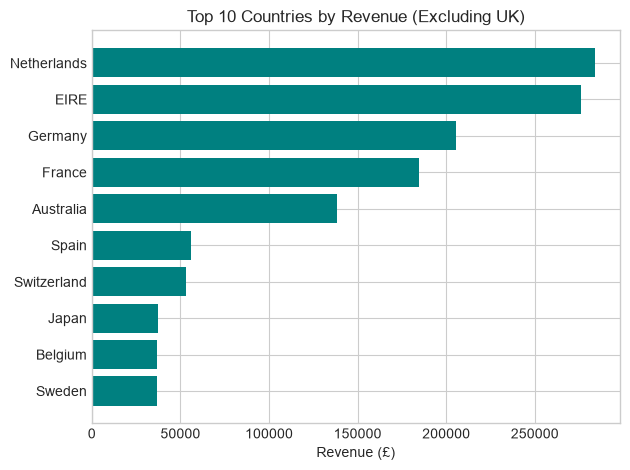

In [165]:
count_summary = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)
top_countries_NO_UK = count_summary.drop("United Kingdom").head(10)
plt.Figure(figsize=(10, 6))

plt.barh(top_countries_NO_UK.index, top_countries_NO_UK.values, color='teal')
plt.xlabel('Revenue (£)')
plt.title('Top 10 Countries by Revenue (Excluding UK)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../PIctures/Picountry_revenue.png', dpi=120)

### Country Revenue (UK Excluded)

- The Netherlands and EIRE (Ireland) generate the highest revenue after the UK, indicating significantly stronger demand compared to other countries.

# Monthly Sales Trend

In [166]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('InvoiceMonth')['TotalPrice'].sum()

print(monthly_sales)

InvoiceMonth
2010-12     776314.95
2011-01     670639.46
2011-02     508081.54
2011-03     690591.84
2011-04     515869.66
2011-05     740472.33
2011-06     738233.99
2011-07     688802.67
2011-08     724708.16
2011-09    1029245.38
2011-10    1104030.92
2011-11    1453265.98
2011-12     446229.65
Freq: M, Name: TotalPrice, dtype: float64


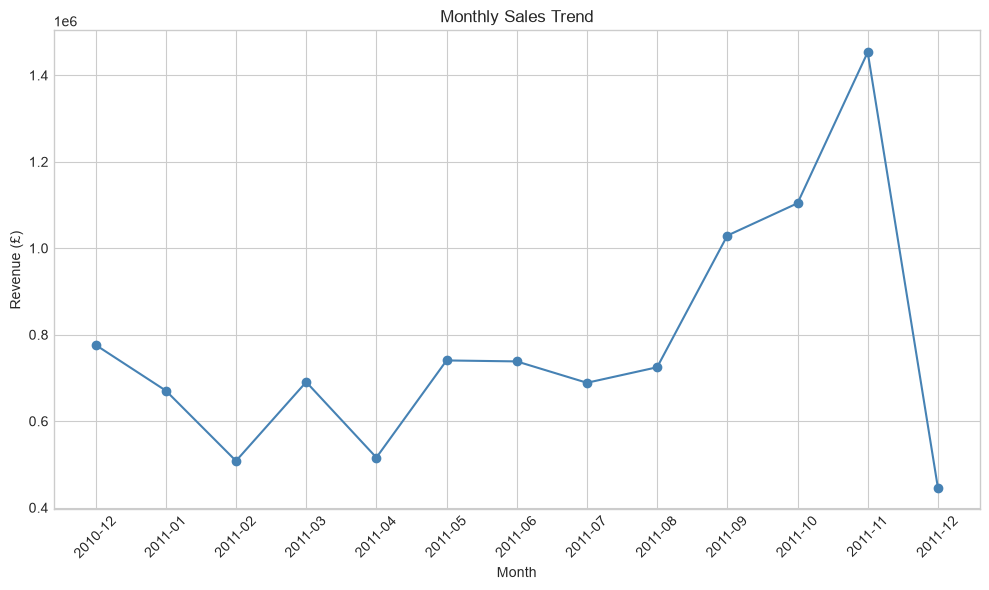

In [167]:
plt.figure(figsize=(10, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o',
    color='steelblue'
)

plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.title('Monthly Sales Trend')

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig('../PIctures/monthly_trend.png', dpi=120)

plt.show()

### Monthly Sales Trend

- Sales show a **clear seasonal pattern**, with a significant increase from September to November, likely driven by holiday shopping and Christmas preparations. December sales are lower because the dataset only contains data up to December 9.

# Customer-Level Purchase Distribution

In [168]:
customer_summary = df.groupby('CustomerID').agg(
    Total_Orders=('InvoiceNo', 'nunique'),
    Total_Spent=('TotalPrice', 'sum')
)

print(customer_summary.describe())

       Total_Orders    Total_Spent
count   4334.000000    4334.000000
mean       4.246424    1978.644218
std        7.642618    8554.404492
min        1.000000       2.900000
25%        1.000000     304.250000
50%        2.000000     662.565000
75%        5.000000    1630.525000
max      206.000000  279138.020000


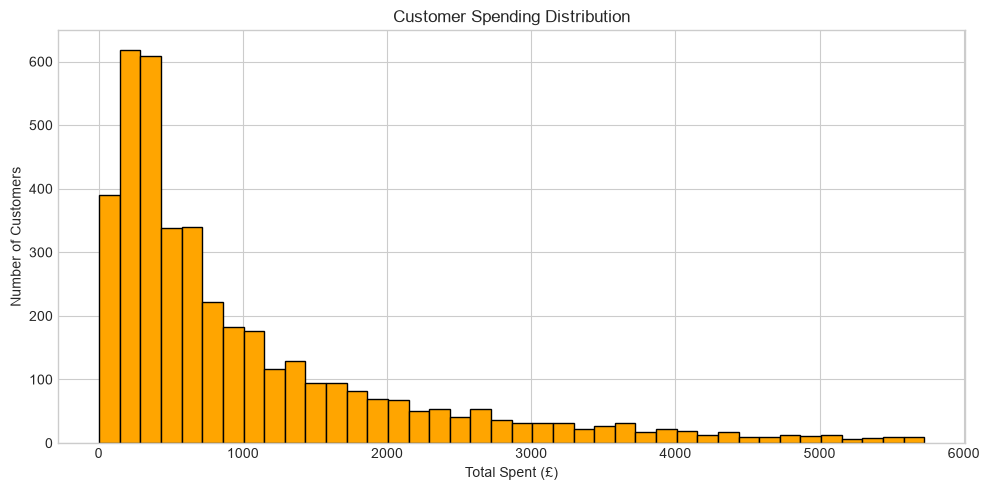

In [169]:
df_customer = df.dropna(subset=['CustomerID'])
customer_spend = df_customer.groupby('CustomerID')['TotalPrice'].sum()
capped = customer_spend[customer_spend <=  customer_spend.quantile(0.95)]

plt.figure(figsize=(10, 5))
plt.hist(capped, bins=40, color='orange', edgecolor='black')
plt.xlabel('Total Spent (£)')
plt.ylabel('Number of Customers')
plt.title('Customer Spending Distribution')
plt.tight_layout()
plt.savefig('../PIctures/customer_distribution.png', dpi=120)


### Customer Spending Distribution

- Customer spending is **strongly right-skewed**. Most customers spend between £0 and £1,000, while only a small number of customers have very high spending. This highlights the importance of **RFM segmentation**, as the average customer does not accurately represent the overall customer base.

In [170]:
numeric_cols = df[['Quantity', 'UnitPrice', 'TotalPrice']]
correlation_matrix = numeric_cols.corr()
print(correlation_matrix)

            Quantity  UnitPrice  TotalPrice
Quantity    1.000000  -0.031070    0.845025
UnitPrice  -0.031070   1.000000    0.120848
TotalPrice  0.845025   0.120848    1.000000


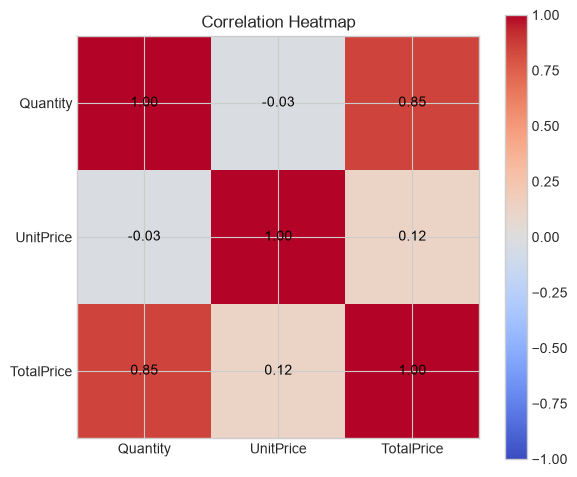

In [171]:
corr = numeric_cols.corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns)
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', color='black')

plt.title('Correlation Heatmap')
plt.colorbar(im)
plt.tight_layout()
plt.savefig('../PIctures/correlation_heatmap.png', dpi=120)
plt.show()

In [172]:
print('Missing CustomerID: ', df['CustomerID'].isnull().sum())

df_customers = df.dropna(subset=['CustomerID']).copy()
df_customers['CustomerID'] = df_customers['CustomerID'].astype(int)

print('Shape after removing missing CustomerID:', df_customer.shape)

Missing CustomerID:  131426
Shape after removing missing CustomerID: (391282, 10)


# Calculating Recency 

In [173]:
print('Last date in data:', df_customer['InvoiceDate'].max())

import datetime as dt
reference_date = df_customers['InvoiceDate'].max() + dt.timedelta(days=1)
print('Reference date:', reference_date)

Last date in data: 2011-12-09 12:50:00
Reference date: 2011-12-10 12:50:00


# Making RFM Table

In [174]:
rfm = df_customers.groupby('CustomerID').agg(
    Recency =('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
)

print(rfm.head(10))
print()
print(rfm.describe())

            Recency  Frequency  Monetary
CustomerID                              
12346           326          1  77183.60
12347             2          7   4310.00
12348            75          4   1437.24
12349            19          1   1457.55
12350           310          1    294.40
12352            36          7   1385.74
12353           204          1     89.00
12354           232          1   1079.40
12355           214          1    459.40
12356            23          3   2487.43

           Recency    Frequency       Monetary
count  4334.000000  4334.000000    4334.000000
mean     92.750346     4.246424    1978.644218
std     100.182135     7.642618    8554.404492
min       1.000000     1.000000       2.900000
25%      18.000000     1.000000     304.250000
50%      51.000000     2.000000     662.565000
75%     143.000000     5.000000    1630.525000
max     374.000000   206.000000  279138.020000


In [175]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm[['Recency','Frequency','Monetary']])

rfm_scaled = pd.DataFrame(rfm_scaled, columns=['Recency','Frequency','Monetary'],
                                            index=rfm.index)
print(rfm_scaled.head())
print()
print(rfm_scaled.describe())



             Recency  Frequency  Monetary
CustomerID                               
12346       2.328525  -0.424828  8.792387
12347      -0.905958   0.360334  0.272564
12348      -0.177201  -0.032247 -0.063297
12349      -0.736248  -0.424828 -0.060922
12350       2.168797  -0.424828 -0.196909

            Recency     Frequency      Monetary
count  4.334000e+03  4.334000e+03  4.334000e+03
mean  -7.049686e-17  1.967354e-17  2.787085e-17
std    1.000115e+00  1.000115e+00  1.000115e+00
min   -9.159411e-01 -4.248280e-01 -2.309889e-01
25%   -7.462306e-01 -4.248280e-01 -1.957573e-01
50%   -4.167925e-01 -2.939677e-01 -1.538659e-01
75%    5.016409e-01  9.861324e-02 -4.069943e-02
max    2.807707e+00  2.640154e+01  3.240335e+01


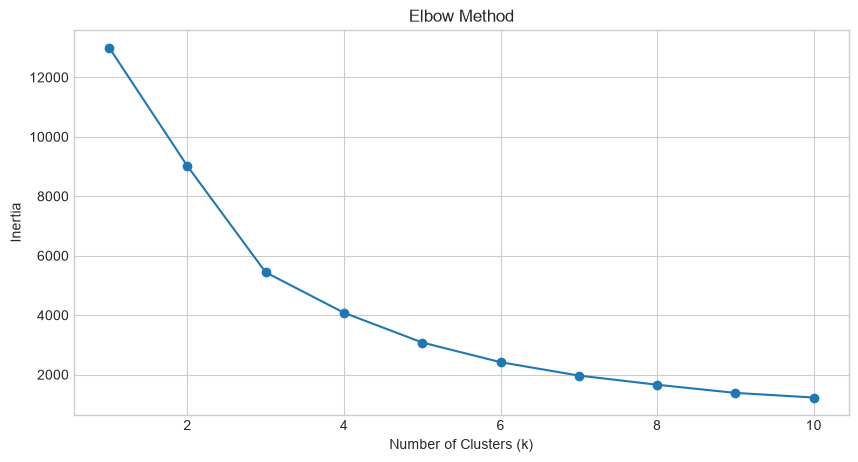

In [176]:
from sklearn.cluster import KMeans

inertia =[]
k_range = range(1,11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42,  n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(10,5))
plt.plot(k_range, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.savefig('../PIctures/elbow_plot.png', dpi=120)
plt.show()

In [177]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print(rfm.head(10))
print()
print('Cluster sizes:')
print(rfm['Cluster'].value_counts())

            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346           326          1  77183.60        3
12347             2          7   4310.00        0
12348            75          4   1437.24        0
12349            19          1   1457.55        0
12350           310          1    294.40        2
12352            36          7   1385.74        0
12353           204          1     89.00        2
12354           232          1   1079.40        2
12355           214          1    459.40        2
12356            23          3   2487.43        0

Cluster sizes:
Cluster
0    3044
2    1067
3     211
1      12
Name: count, dtype: int64


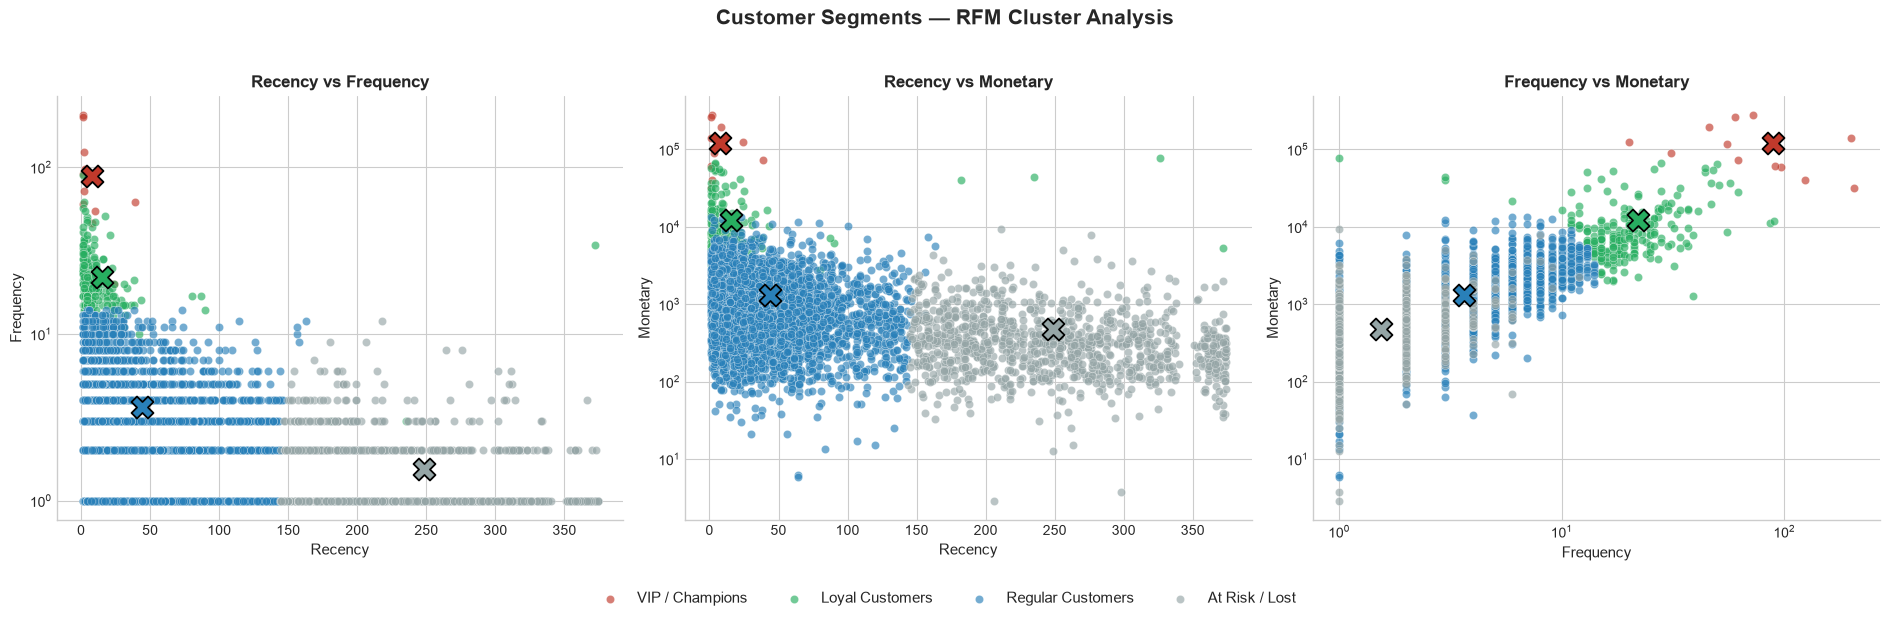

In [178]:

rfm = pd.read_excel('../data/rfm_with_clusters.xlsx', index_col='CustomerID')

cluster_names = {
    0: 'Regular Customers',
    1: 'VIP / Champions',
    2: 'At Risk / Lost',
    3: 'Loyal Customers'
}
rfm['Segment'] = rfm['Cluster'].map(cluster_names)

palette = {
    'VIP / Champions': '#C0392B',      
    'Loyal Customers': '#27AE60',      
    'Regular Customers': '#2980B9',    
    'At Risk / Lost': '#95A5A6'       
}

plt.style.use('seaborn-v0_8-whitegrid')

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
fig.suptitle('Customer Segments — RFM Cluster Analysis', fontsize=15, fontweight='bold', y=1.03)

plot_pairs = [
    ('Recency', 'Frequency', axes[0]),
    ('Recency', 'Monetary', axes[1]),
    ('Frequency', 'Monetary', axes[2])
]

for xcol, ycol, ax in plot_pairs:
    for segment, color in palette.items():
        subset = rfm[rfm['Segment'] == segment]

        ax.scatter(subset[xcol], subset[ycol], label=segment, color=color,
                   alpha=0.65, s=35, edgecolor='white', linewidth=0.3)

        ax.scatter(subset[xcol].mean(), subset[ycol].mean(), color=color,
                   marker='X', s=250, edgecolor='black', linewidth=1.3, zorder=5)

    ax.set_xlabel(xcol, fontsize=11, fontweight='medium')
    ax.set_ylabel(ycol, fontsize=11, fontweight='medium')
    ax.set_title(f'{xcol} vs {ycol}', fontsize=12, fontweight='bold')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    if ycol in ['Monetary', 'Frequency']:
        ax.set_yscale('log')
    if xcol in ['Monetary', 'Frequency']:
        ax.set_xscale('log')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False,
           fontsize=11, bbox_to_anchor=(0.5, -0.08))

plt.tight_layout()
plt.savefig('../PIctures/cluster_scatter_professional.png', dpi=150, bbox_inches='tight')
plt.show()

In [179]:
cluster_profile = rfm.groupby('Cluster')[[
    'Recency', 'Frequency', 'Monetary']].mean()

print(cluster_profile.round(1))

         Recency  Frequency  Monetary
Cluster                              
0           43.8        3.6    1316.3
1            7.9       88.6  122550.8
2          248.5        1.5     474.2
3           15.4       21.9   12284.8


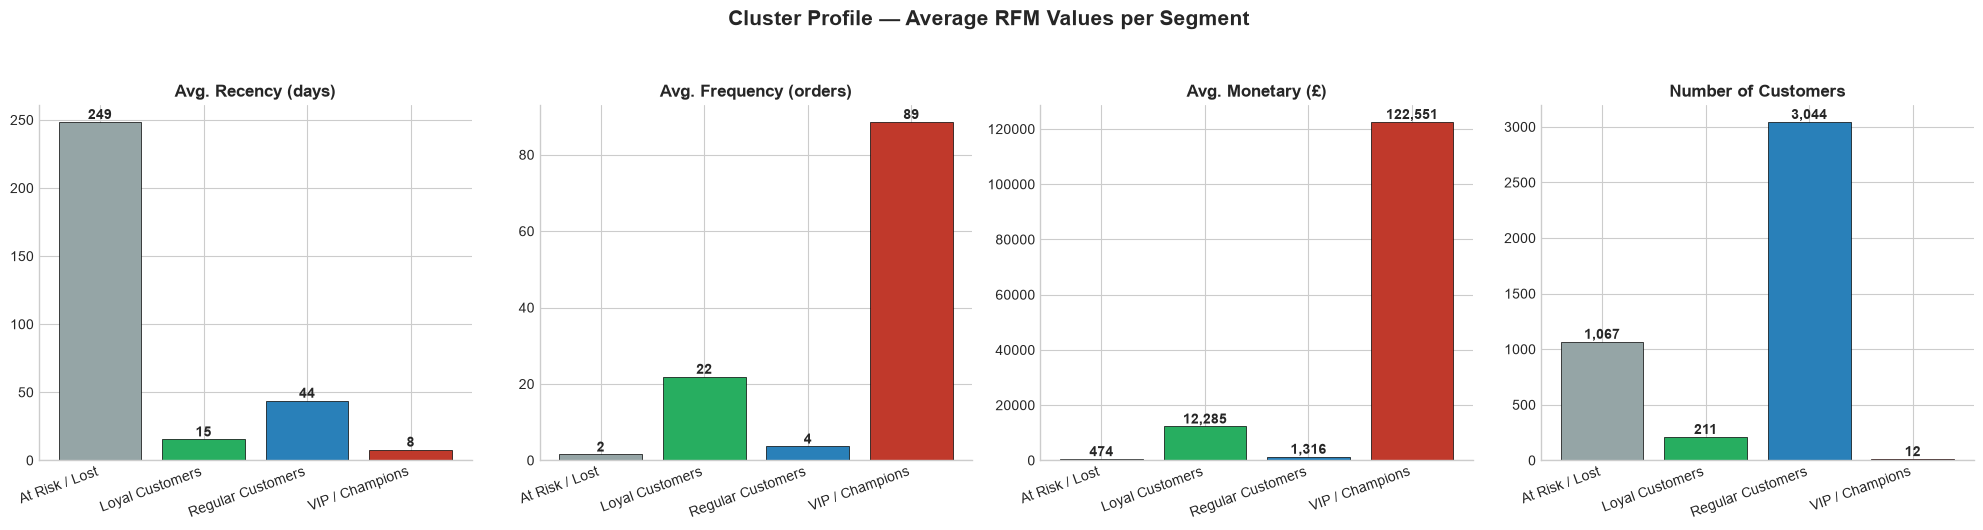

In [180]:

cluster_names = {
    0: 'Regular Customers',
    1: 'VIP / Champions',
    2: 'At Risk / Lost',
    3: 'Loyal Customers'
}
rfm['Segment'] = rfm['Cluster'].map(cluster_names)

cluster_profile = rfm.groupby('Segment')[['Recency', 'Frequency', 'Monetary']].mean()
cluster_profile['Count'] = rfm['Segment'].value_counts()

palette = {
    'VIP / Champions': '#C0392B',
    'Loyal Customers': '#27AE60',
    'Regular Customers': '#2980B9',
    'At Risk / Lost': '#95A5A6'
}

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('Cluster Profile — Average RFM Values per Segment', fontsize=15, fontweight='bold', y=1.05)

metrics = ['Recency', 'Frequency', 'Monetary', 'Count']
titles = ['Avg. Recency (days)', 'Avg. Frequency (orders)', 'Avg. Monetary (£)', 'Number of Customers']

for ax, metric, title in zip(axes, metrics, titles):
    colors = [palette[seg] for seg in cluster_profile.index]
    bars = ax.bar(cluster_profile.index, cluster_profile[metric], color=colors, edgecolor='black', linewidth=0.5)

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height,
                f'{height:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

    ax.set_title(title, fontsize=12, fontweight='bold')

    # FIX: pehle ticks set karna, phir labels
    ax.set_xticks(range(len(cluster_profile.index)))
    ax.set_xticklabels(cluster_profile.index, rotation=20, ha='right')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../PIctures/cluster_profile_bars.png', dpi=150, bbox_inches='tight')
plt.show()

In [181]:
rfm.to_excel('rfm_with_clusters.xlsx')
print('File saved as rfm_with_clusters.xlsx')

File saved as rfm_with_clusters.xlsx


In [182]:
rfm.head()

,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346,326,1,77183.60,3,Loyal Customers
12347,2,7,4310.00,0,Regular Customers
12348,75,4,1437.24,0,Regular Customers
12349,19,1,1457.55,0,Regular Customers
12350,310,1,294.40,2,At Risk / Lost


In [183]:
from sklearn.model_selection import train_test_split


X = rfm[['Recency', 'Frequency', 'Monetary']]
y = rfm['Cluster']

X_train, X_test, y_train, y_test = train_test_split(
                    X, y, test_size=0.2, random_state=42)

print('Training set size:', X_train.shape)
print('Testing set size:', X_test.shape)


Training set size: (3467, 3)
Testing set size: (867, 3)


In [184]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
print('Model trained!')
model.fit(X_train, y_train)


Model trained!


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [185]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print('Accuracy:', accuracy)


print('\n Classification Report:\n')
print(classification_report(y_test, y_pred))

Accuracy: 0.9988465974625144

 Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       603
           2       1.00      1.00      1.00       220
           3       1.00      0.98      0.99        44

    accuracy                           1.00       867
   macro avg       1.00      0.99      1.00       867
weighted avg       1.00      1.00      1.00       867



## Insight: Small Cluster Evaluation Challenge

Cluster 1 (only 12 customers) does not appear in the classification report. This is because 
the cluster is so small that, after an 80/20 train-test split, it's likely that none of its 
12 customers ended up in the test set — or too few did to be evaluated reliably.

This highlights an important challenge in customer segmentation projects: very small clusters 
(often representing extreme outliers or a handful of VIP customers) are statistically difficult 
to evaluate with standard train-test splits, since there may not be enough samples to test 
against. In practice, this can be addressed by:

- Using stratified train-test splitting to ensure every cluster is represented in both sets
- Applying cross-validation instead of a single train-test split
- Treating very small/outlier clusters separately (e.g., flagging them manually rather than 
  relying on the classifier)

In [186]:
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print('Training Accuracy:', train_acc)  
print('Testing Accuracy:', test_acc)     

Training Accuracy: 1.0
Testing Accuracy: 0.9988465974625144


In [187]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, X, y, cv=5)

print('Scores for each fold:', scores)
print('Average Accuracy:', scores.mean())
print('Standard Deviation:', scores.std())

Scores for each fold: [0.99538639 0.99538639 0.99653979 0.99538639 0.99769053]
Average Accuracy: 0.9960778986231091
Standard Deviation: 0.0009217898627981574


## Insight: Cross-Validation Results

To verify that the 99.88% test accuracy wasn't a result of a "lucky" train-test split, 
5-fold cross-validation was performed on the full dataset.

**Results across 5 folds:**
- Fold accuracies: 99.54%, 99.54%, 99.65%, 99.54%, 99.77%
- Average accuracy: 99.61%
- Standard deviation: 0.0009 (extremely low)

**What this tells us:**
The consistently high accuracy across all 5 folds — with almost no variation between them — 
confirms that the model's performance is stable and not dependent on which specific customers 
ended up in the training vs. test set. This rules out the possibility that the earlier high 
accuracy was a fluke caused by a favorable random split.

However, this consistency also reinforces that the high accuracy stems from target leakage 
rather than the model learning a genuinely difficult pattern: since the Cluster labels were 
derived directly from the same Recency, Frequency, and Monetary features used to predict them, 
the classification task is mathematically straightforward regardless of how the data is split. 
In a real-world scenario where the target is independent of the input features, this level of 
accuracy (and this level of consistency) would be highly unusual and worth investigating further 
for data leakage.

In [188]:
from sklearn.metrics import silhouette_score

score = silhouette_score(rfm_scaled, rfm['Cluster'])
print('Silhouette Score:', score)

Silhouette Score: 0.615832023763432


In [189]:
from sklearn.cluster import KMeans

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    print(f'k={k}: Silhouette Score = {score:.4f}')

k=2: Silhouette Score = 0.8985
k=3: Silhouette Score = 0.5927
k=4: Silhouette Score = 0.6158
k=5: Silhouette Score = 0.6005
k=6: Silhouette Score = 0.5956


## Insight: Silhouette Score vs. Business Interpretability Trade-off

When comparing Silhouette Scores across different values of k, k=2 produced the highest 
score (0.8985), while k=4 (the value chosen for this analysis) scored lower at 0.6158.

**Scores by k:**
- k=2: 0.8985
- k=3: 0.5927
- k=4: 0.6158
- k=5: 0.6005
- k=6: 0.5956

Despite k=2 being the statistically "tightest" clustering solution, it was not selected. 
A 2-cluster split would likely separate customers into a simple "high spenders" vs. 
"low spenders" grouping — mathematically clean, but too coarse to be useful for business 
decision-making.

k=4 was chosen instead because it produces segments that map directly to actionable 
marketing strategies: VIP/Champions, Loyal Customers, Regular Customers, and At-Risk/Lost 
customers. Each segment supports a distinct business action (e.g., retention campaigns for 
at-risk customers, loyalty rewards for champions), which a 2-cluster solution cannot provide.

This illustrates a common trade-off in unsupervised learning: the mathematically optimal 
solution (highest silhouette score) is not always the most useful one. Cluster selection 
should balance statistical validity with domain relevance and interpretability — a model 
whose output cannot be acted upon has limited practical value, regardless of how well it 
scores on internal metrics.

In [190]:
import joblib

joblib.dump(kmeans, '../Models/kmeans_model.pkl')
joblib.dump(scaler, '../Models/scaler.pkl')
joblib.dump(model, '../Models/random_forest_model.pkl')   

print('Models saved!')

Models saved!


## Market Basket Analysis

In [191]:
print('Unique invoices:', df['InvoiceNo'].nunique())
print('Unique products:', df['Description'].nunique())

Unique invoices: 19775
Unique products: 4017


In [192]:
df_uk = df[df['Country'] == 'United Kingdom']

top_products = df_uk['Description'].value_counts().head(100).index
df_basket = df_uk[df_uk['Description'].isin(top_products)]

print('Filtered shape:', df_basket.shape)
print('Invoices in filtered data:', df_basket['InvoiceNo'].nunique())

Filtered shape: (88523, 10)
Invoices in filtered data: 14345


In [193]:
# Pivot table banana: har row = invoice, har column = product, value = quantity
basket = df_basket.groupby(['InvoiceNo', 'Description'])['Quantity'].sum().unstack().fillna(0)

print(basket.shape)
print(basket.iloc[:5, :5])

(14345, 100)
Description  6 RIBBONS RUSTIC CHARM  60 TEATIME FAIRY CAKE CASES  \
InvoiceNo                                                          
536365                          0.0                          0.0   
536367                          0.0                          0.0   
536368                          0.0                          0.0   
536371                          0.0                          0.0   
536373                          0.0                          0.0   

Description  ALARM CLOCK BAKELIKE GREEN  ALARM CLOCK BAKELIKE PINK  \
InvoiceNo                                                            
536365                              0.0                        0.0   
536367                              0.0                        0.0   
536368                              0.0                        0.0   
536371                              0.0                        0.0   
536373                              0.0                        0.0   

Description  ALARM 

In [194]:
def encode_units(x):
    if x <= 0:
        return 0
    else:
        return 1

basket_encoded = basket.map(encode_units)  
print(basket_encoded.iloc[:5, :5])

Description  6 RIBBONS RUSTIC CHARM  60 TEATIME FAIRY CAKE CASES  \
InvoiceNo                                                          
536365                            0                            0   
536367                            0                            0   
536368                            0                            0   
536371                            0                            0   
536373                            0                            0   

Description  ALARM CLOCK BAKELIKE GREEN  ALARM CLOCK BAKELIKE PINK  \
InvoiceNo                                                            
536365                                0                          0   
536367                                0                          0   
536368                                0                          0   
536371                                0                          0   
536373                                0                          0   

Description  ALARM CLOCK BAKELIK

In [195]:
from mlxtend.frequent_patterns import apriori, association_rules

frequent_itemsets = apriori(basket_encoded, min_support=0.03, use_colnames=True)

print(frequent_itemsets.sort_values('support', ascending=False).head(10))

c:\Users\DELL\anaconda3\envs\statistic\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


     support                                         itemsets
95  0.150715  frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
38  0.134890             frozenset({JUMBO BAG RED RETROSPOT})
75  0.117463            frozenset({REGENCY CAKESTAND 3 TIER})
65  0.111049                       frozenset({PARTY BUNTING})
53  0.097037             frozenset({LUNCH BAG RED RETROSPOT})
6   0.095573       frozenset({ASSORTED COLOUR BIRD ORNAMENT})
81  0.086511   frozenset({SET OF 3 CAKE TINS PANTRY DESIGN })
59  0.084977     frozenset({NATURAL SLATE HEART CHALKBOARD })
48  0.084768             frozenset({LUNCH BAG  BLACK SKULL.})
25  0.081143               frozenset({HEART OF WICKER SMALL})


In [196]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1)
rules = rules.sort_values('lift', ascending=False)

print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))

                                          antecedents  \
87        frozenset({PINK REGENCY TEACUP AND SAUCER})   
86  frozenset({ROSES REGENCY TEACUP AND SAUCER , G...   
85  frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...   
88       frozenset({GREEN REGENCY TEACUP AND SAUCER})   
84  frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...   
89      frozenset({ROSES REGENCY TEACUP AND SAUCER })   
9        frozenset({GREEN REGENCY TEACUP AND SAUCER})   
8         frozenset({PINK REGENCY TEACUP AND SAUCER})   
75      frozenset({ROSES REGENCY TEACUP AND SAUCER })   
74        frozenset({PINK REGENCY TEACUP AND SAUCER})   

                                          consequents   support  confidence  \
87  frozenset({ROSES REGENCY TEACUP AND SAUCER , G...  0.034298    0.700855   
86        frozenset({PINK REGENCY TEACUP AND SAUCER})  0.034298    0.702857   
85       frozenset({GREEN REGENCY TEACUP AND SAUCER})  0.034298    0.902752   
88  frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...  0

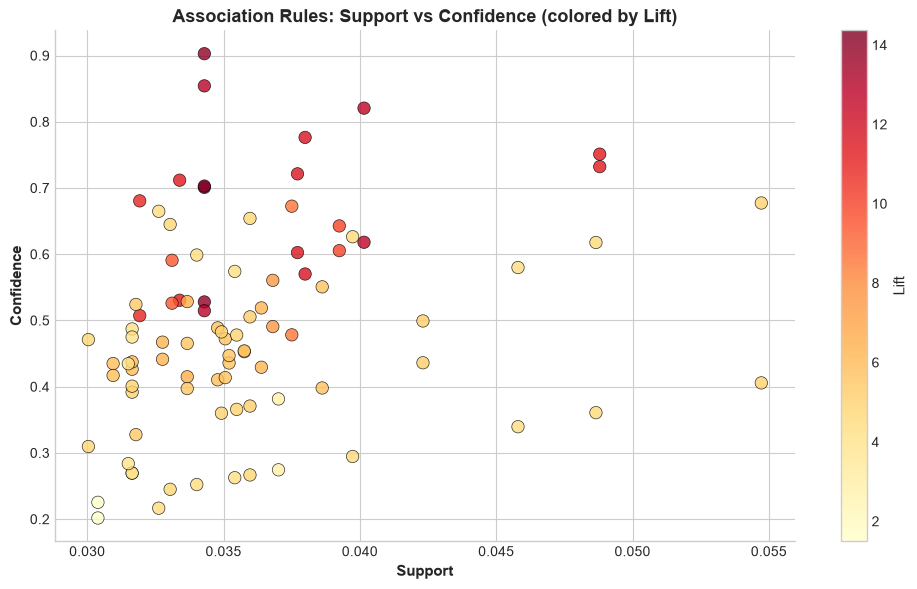

In [197]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(rules['support'], rules['confidence'],
                      c=rules['lift'], cmap='YlOrRd', s=80,
                      edgecolor='black', linewidth=0.5, alpha=0.8)

ax.set_xlabel('Support', fontsize=11, fontweight='bold')
ax.set_ylabel('Confidence', fontsize=11, fontweight='bold')
ax.set_title('Association Rules: Support vs Confidence (colored by Lift)',
              fontsize=13, fontweight='bold')

cbar = plt.colorbar(scatter)
cbar.set_label('Lift', fontsize=11)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../Pictures/basket_rules_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

## Insight: Support vs Confidence Scatter Plot

This chart plots all discovered association rules by Support (x-axis) and Confidence 
(y-axis), with point color representing Lift (yellow = low, dark red = high).

A clear pattern emerges: the highest-lift rules (dark red points) cluster in the 
low-support, high-confidence region (top-left). This makes sense — a rule can only 
achieve very high lift when the item combination is fairly rare (low support) but, 
whenever it does occur, is almost always accompanied by the associated product 
(high confidence).

Conversely, the highest-support rules (bottom-right, support > 0.045) tend to have 
lower lift, since these involve more generally popular products whose co-occurrence 
is less distinctive — they sell together often simply because they both sell often 
individually, not because of a strong specific relationship.

**Business takeaway:** High-lift, low-support rules (top-left) are ideal candidates 
for targeted cross-sell recommendations or bundling, since they represent a strong, 
specific buying pattern — even though relatively few customers exhibit it. High-support 
rules are better suited for broad store-layout decisions, since they affect a larger 
share of transactions.

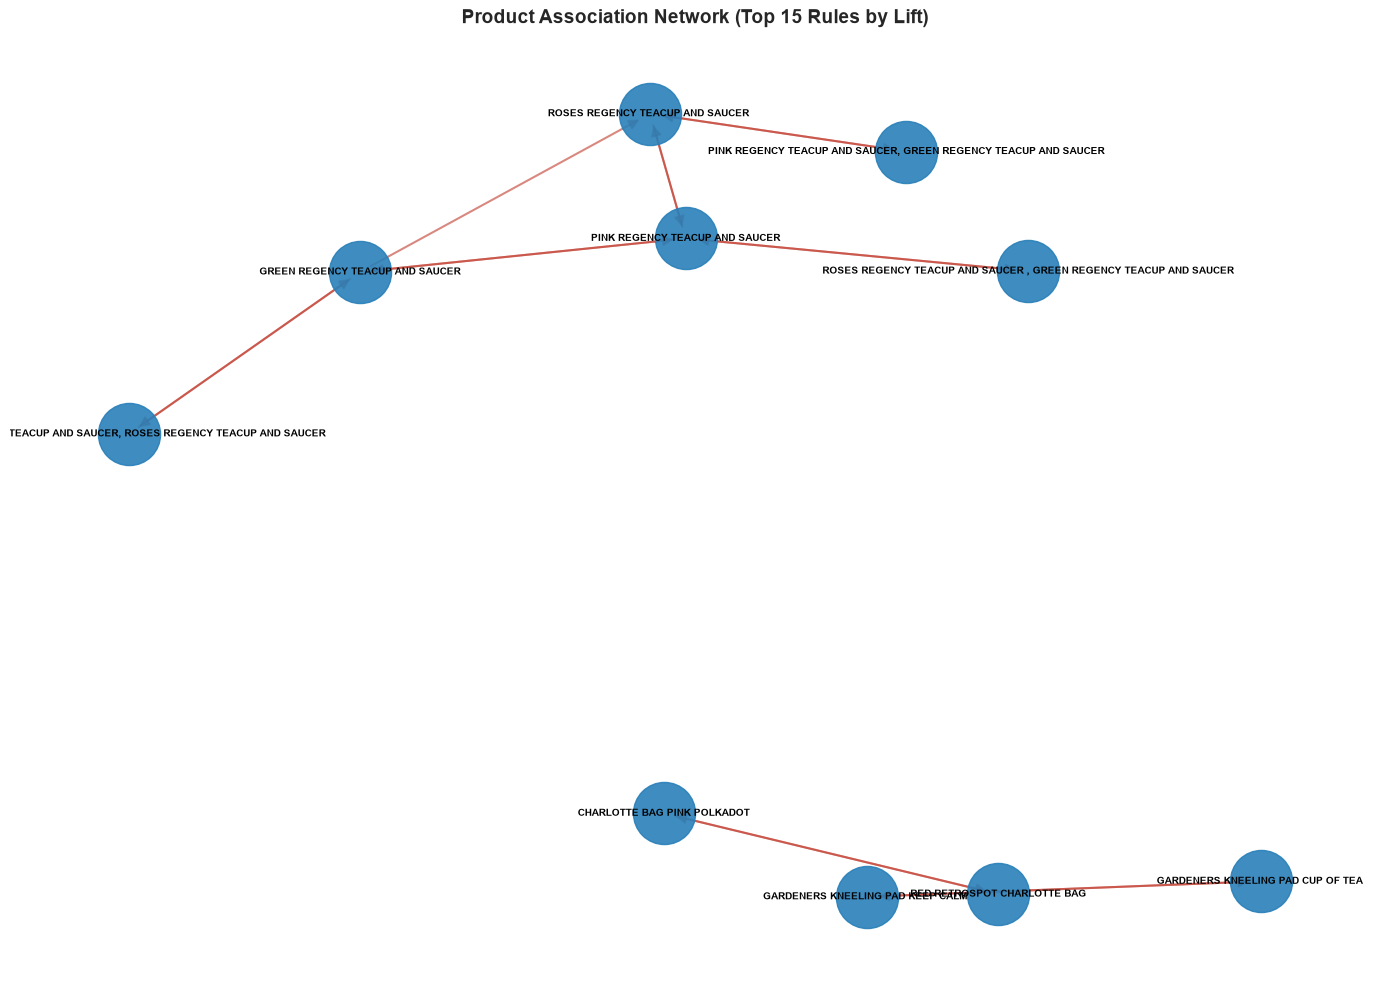

In [198]:
import networkx as nx

top_rules = rules.sort_values('lift', ascending=False).head(15)

G = nx.DiGraph()

for _, row in top_rules.iterrows():
    antecedent = ', '.join(list(row['antecedents'])) if isinstance(row['antecedents'], frozenset) else row['antecedents']
    consequent = ', '.join(list(row['consequents'])) if isinstance(row['consequents'], frozenset) else row['consequents']
    G.add_edge(antecedent, consequent, weight=row['lift'])

plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=1.5, seed=42)

nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='#2980B9', alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=7, font_weight='bold')
nx.draw_networkx_edges(G, pos, edge_color='#C0392B', arrows=True, arrowsize=15, width=1.5, alpha=0.6)

plt.title('Product Association Network (Top 15 Rules by Lift)', fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig('../Pictures/basket_network_graph.png', dpi=150, bbox_inches='tight')
plt.show()

## Insight: Product Association Network Graph

The network graph visualizes the top 15 rules by lift as a directed graph, where an 
arrow from Product A to Product B means "customers who bought A were also likely to 
buy B."

The graph reveals two distinct, disconnected clusters rather than one large web of 
relationships:

1. **The Regency Teacup & Saucer cluster** (Pink, Green, Roses) — these three products 
   are tightly interconnected with arrows going in multiple directions between all three, 
   confirming they function as a "collectible set." Customers buying one color are highly 
   likely to buy the others.

2. **A smaller, separate cluster** (Charlotte Bag, Gardeners Kneeling Pad, Red Retrospot 
   Charlotte Bag) — a different, unrelated buying pattern among gardening/bag-themed items.

The fact that these clusters are disconnected (no edges linking them) confirms that the 
top associations in this dataset are driven by a small number of distinct, unrelated 
product groupings rather than one dominant shopping pattern. This is useful for the 
business to know: cross-sell strategies should be designed per product cluster, not as 
a single one-size-fits-all recommendation engine.

In [199]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

df_uk = df[df['Country'] == 'United Kingdom']
top_products = df_uk['Description'].value_counts().head(100).index
df_basket = df_uk[df_uk['Description'].isin(top_products)]

basket = df_basket.groupby(['InvoiceNo', 'Description'])['Quantity'].sum().unstack().fillna(0)

basket_encoded = (basket > 0).astype(int)
basket_encoded = basket_encoded.astype(bool)

frequent_itemsets = apriori(basket_encoded, min_support=0.03, use_colnames=True)

rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1)
rules = rules.sort_values('lift', ascending=False)

rules['antecedents'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequents'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))

save_path = '../data/association_rules.xlsx'
rules.to_excel(save_path, index=False)

print('Saved!')
print('Total rules saved:', len(rules))

Saved!
Total rules saved: 90


## 📊 Project Overview & Conclusion

### Objective
This project analyzes ~540,000 transactions from a UK-based online retailer to answer two 
core business questions: **who are our customers, and what products drive cross-selling 
opportunities?** Since the raw dataset had no target variable, this project's central task 
was to engineer one — using unsupervised learning to derive meaningful customer segments 
directly from behavioral data.

### Workflow Summary

| Stage | What Was Done |
|---|---|
| **Data Cleaning** | Removed duplicates, cancelled/adjustment orders, non-product stock codes, invalid prices/quantities, and an extreme outlier — reducing noise from 541,909 to ~522,700 clean transactions |
| **EDA** | Analyzed revenue, top products, country-level sales, monthly trends, and feature correlations |
| **Feature Engineering** | Built RFM (Recency, Frequency, Monetary) metrics per customer |
| **Segmentation** | Applied K-Means clustering (k=4, selected via Elbow Method, validated with a Silhouette Score of 0.62) to group 4,334 customers into four segments |
| **Classification** | Trained a Random Forest Classifier to predict a customer's segment from RFM values, validated with train-test split and 5-fold cross-validation |
| **Market Basket Analysis** | Applied the Apriori algorithm to uncover product association rules and cross-sell opportunities |
| **Deployment** | Saved trained models and built an interactive Streamlit dashboard with live segment prediction |

### Key Findings

- **Revenue concentration:** The UK accounts for 84.8% of total revenue, with the Netherlands 
  and Ireland as the next largest markets.
- **Customer value is highly skewed:** A small number of high-frequency customers 
  disproportionately drive revenue — the median customer spends £662, while the top 
  customer spent over £279,000.
- **Four actionable segments emerged:**
  - 🏆 **VIP / Champions** (12 customers) — extremely high frequency and spend; the 
    highest-value group despite its small size.
  - ⭐ **Loyal Customers** (211) — frequent, recent, solid spenders.
  - 👤 **Regular Customers** (3,044) — the largest group, low activity, a conversion 
    opportunity.
  - ⚠️ **At Risk / Lost** (1,067) — haven't purchased in ~249 days on average; the 
    primary target for win-back campaigns.
- **Product bundling opportunity:** The Pink, Green, and Roses Regency Teacup & Saucer 
  sets are purchased together far more often than chance (lift ≈ 12–14), suggesting a 
  natural bundling/collection strategy.
- **Model validity:** While the classifier achieved ~99.6% cross-validated accuracy, this 
  reflects that the target was mathematically derived from the same RFM features used to 
  predict it (target leakage) — not evidence of a difficult real-world pattern. This 
  distinction is important context for interpreting the result honestly.

### Business Recommendations
1. Launch a **win-back campaign** targeting the At-Risk segment (1,067 customers) before 
   they fully churn.
2. Design a **loyalty/VIP program** to protect and grow the small but highly valuable 
   Champions segment.
3. Test a **bundled product offer** for the Regency Teacup & Saucer collection based on 
   the market basket findings.
4. Use the trained classifier to score new customers in real time and route them to the 
   appropriate marketing treatment as soon as their purchase history builds up.

### Limitations & Future Work
- The dataset covers a single year (Dec 2010–Dec 2011) from one retailer, limiting 
  generalizability.
- RFM-based clustering does not account for product category preferences or seasonality — 
  incorporating these could refine segments further.
- The classifier's high accuracy is a product of the labeling process rather than a 
  validated real-world predictive task; a genuinely useful next step would be predicting 
  *future* segment migration (e.g., will this customer become At-Risk next quarter?) using 
  time-based train/test splits.
- Market basket analysis was restricted to the UK and top 100 products for performance; 
  expanding this could surface additional cross-sell opportunities.

### Tech Stack
Python · pandas · scikit-learn · mlxtend · matplotlib · networkx · Streamlit · joblib

---
**Author:** Usman Haider